# 02. Performance and risk

**Purpose.** Compute the descriptive performance and risk metrics for BBCA, BBRI, BMRI and the IHSG, for the full period and for each interest-rate regime. This answers the descriptive research questions (growth, volatility, drawdown, risk-adjusted return) before the CAPM work in notebook 03.

**Metrics covered.** M2 cumulative return, M3 annualized return, M4 annualized volatility, M6 Sharpe ratio (full, rolling 252 days, per regime, with a block-bootstrap interval) and M9 maximum drawdown. Definitions are in `metric_definitions.md`; the formulas live in `scripts/metrics.py`.

**How to run.** Select the project `.venv` as the kernel, then use *Restart* and *Run All*. The notebook asks for the PostgreSQL user and password at the first data cell. It only reads from the database. The bootstrap step takes roughly a minute. Tables are also saved as CSV files in `reports/` (ignored by git) for the Tableau cross-check.

**Basis.** Primary results use the split-adjusted `close` (price return, dividends excluded). The `adj_close` sensitivity is a separate step (total-return sensitivity, M10) and is not run here.

**Read these before using the numbers.**
- Annualization uses 252 trading days, but the data has about 241 a year, so annualized volatility and Sharpe are scaled by an approximation of about 2%.
- The regimes have unequal lengths (399, 499, 393 and 90 return days). The Stub (from 20 May 2026) is descriptive only: no annualized return and no bootstrap interval.
- BMRI's 11 May 2026 ex-dividend drop is read as a loss in the price series.
- Everything here is in-sample and descriptive.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
try:
    import db_access
    import metrics
except ImportError as exc:
    raise ImportError(
        f"{exc}\nThis kernel is {sys.executable}. Select the project .venv kernel "
        "(top right of the notebook, Select Kernel > Python Environments > .venv), then Restart and Run All."
    ) from exc

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
print("project root:", ROOT)

project root: d:\Data Analyst\Portfolio


## 1. Load the data

Two reads, both `SELECT` only. `core.price_daily` gives the prices; `analytics.excess_return_daily` is used only for its policy rate (`rate_pct`) and to cross-check the Python excess returns. Returns are then computed in Python with `metrics.py`, the same calculation that notebook 01 showed equals the SQL views.

In [2]:
conn = db_access.connect()
try:
    prices = db_access.load_prices(conn)
    sql = db_access.load_excess_returns(conn)
finally:
    conn.close()

print("prices rows:", len(prices), "| SQL view rows:", len(sql))

prices rows: 5536 | SQL view rows: 5524


## 2. Settings and a small helper

The expected counts and the four cumulative price returns are the values already confirmed during the SQL validation. They are used below as a check that `metrics.py` behaves correctly on the real data. The cumulative returns were recorded to two decimals in percent, so the tolerance is 0.005 percentage points.

In [3]:
TICKERS = ["BBCA", "BBRI", "BMRI", "IHSG"]
FIRST_RETURN_DAY = pd.Timestamp("2021-01-04")
PRIOR_CLOSE_DAY = pd.Timestamp("2020-12-30")
EXPECTED_DAYS = 1381
REGIME_DAYS = {"R1": 399, "R2": 499, "R3": 393, "Stub": 90}
KNOWN_CUM = {"BBCA": -0.1027, "BBRI": -0.1717, "BMRI": 0.2680, "IHSG": 0.0154}
KNOWN_CUM_TOL = 5e-5
RET_TOL = 1e-12

# Bootstrap settings: docs/metric_definitions.md, design decision 3.
N_BOOT = 10_000
BLOCK = 10
SENSITIVITY_BLOCKS = (5, 21)
SEED = 20260101
LEVEL = 0.95

# Fixed colour per instrument (never repainted); the index is neutral grey and dashed.
COLORS = {"BBCA": "#2a78d6", "BBRI": "#eb6834", "BMRI": "#1baf7a", "IHSG": "#52514e"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d3"

results = []


def check(name, ok, detail=""):
    results.append(bool(ok))
    print(f"{'PASS' if ok else 'FAIL'}  {name}" + (f"  [{detail}]" if detail else ""))

## 3. Returns, risk-free rate and excess returns

Returns come from `metrics.simple_returns` on the full price history, keeping dates from 2021-01-04 (so the first return has a correct prior close). The daily risk-free rate is the policy rate divided by 100 and by 252. Excess return is the return minus that rate.

In [4]:
close = db_access.to_wide(prices, "close")[TICKERS]
ret = metrics.simple_returns(close, FIRST_RETURN_DAY)

rate = sql.drop_duplicates("trade_date").set_index("trade_date")["rate_pct"].sort_index()
rf = metrics.daily_risk_free(rate)
excess = metrics.excess_return(ret, rf)

sql_excess = db_access.to_wide(sql, "excess_close")[TICKERS]
labels = metrics.assign_regime(ret.index)
counts = labels.value_counts()

check("return dates equal SQL view dates", ret.index.equals(sql_excess.index), f"{len(ret)} days")
check(f"{EXPECTED_DAYS} return days", len(ret) == EXPECTED_DAYS)
check("no missing returns or risk-free rates", not ret.isna().any().any() and not excess.isna().any().any())
check("excess returns equal the SQL view", (excess - sql_excess).abs().max().max() < RET_TOL,
      f"max abs diff {(excess - sql_excess).abs().max().max():.2e}")
check("regime day counts", all(counts[r] == n for r, n in REGIME_DAYS.items()), str(REGIME_DAYS))

PASS  return dates equal SQL view dates  [1381 days]
PASS  1381 return days
PASS  no missing returns or risk-free rates
PASS  excess returns equal the SQL view  [max abs diff 2.77e-16]
PASS  regime day counts  [{'R1': 399, 'R2': 499, 'R3': 393, 'Stub': 90}]


## 3a. Data check: largest daily moves and 8 June 2026

All four instruments reach their full-period maximum drawdown on 2026-06-08, and the rolling Sharpe ratio drops sharply that day and recovers within days. A one-day collapse across all four followed by a quick rebound can be a real market shock or a bad price. Because that day drives the full-period drawdowns and the Stub results, this section lists what the data shows so it can be checked against an outside source (Yahoo Finance or the IDX website).

This section is informational. It has no PASS or FAIL.
- **Largest moves:** the five largest absolute daily returns per instrument, and the number of days above 8% (the specification logs these and does not remove them).
- **Clusters:** days on which at least three of the four instruments moved by more than 5%, which points to a market-wide event rather than a single-stock one.
- **Window:** closes and returns from 1 to 16 June 2026. `adj_minus_close` is the adjusted-close return minus the close return in percentage points; a value away from zero means a dividend adjustment fell on that day.

In [5]:
long = ret.rename_axis(columns="ticker").stack().rename("ret").reset_index()
top = (long.assign(abs_ret=long["ret"].abs())
       .sort_values("abs_ret", ascending=False).groupby("ticker").head(5)
       .sort_values(["ticker", "abs_ret"], ascending=[True, False]))
top["ret_pct"] = (100 * top["ret"]).round(2)
top["trade_date"] = top["trade_date"].dt.date
print("Five largest absolute daily returns per instrument")
print(top[["ticker", "trade_date", "ret_pct"]].reset_index(drop=True).to_string())
print("\nDays with an absolute return above 8%:")
print((ret.abs() > 0.08).sum().to_string())

cluster = (ret.abs() > 0.05).sum(axis=1) >= 3
print(f"\nDays when at least three instruments moved by more than 5%: {int(cluster.sum())}")
if cluster.any():
    print((100 * ret[cluster]).round(2).to_string())

window = slice("2026-06-01", "2026-06-16")
sql_adj = db_access.to_wide(sql, "ret_adj")[TICKERS]
view = pd.concat({
    "close": close.loc[window],
    "ret_pct": (100 * ret.loc[window]).round(2),
    "adj_minus_close": (100 * (sql_adj - ret).loc[window]).round(2),
}, axis=1)
print("\n1 to 16 June 2026")
print(view.to_string())

Five largest absolute daily returns per instrument
   ticker  trade_date  ret_pct
0    BBCA  2026-06-10     9.71
1    BBCA  2025-04-08    -8.53
2    BBCA  2025-10-21     7.62
3    BBCA  2022-05-09    -6.46
4    BBCA  2026-06-05    -6.45
5    BBRI  2025-04-08   -10.12
6    BBRI  2025-03-03     9.23
7    BBRI  2026-06-09     7.72
8    BBRI  2025-01-15     7.63
9    BBRI  2025-02-28    -7.44
10   BMRI  2026-06-09    10.24
11   BMRI  2025-04-08   -10.19
12   BMRI  2022-04-28     8.81
13   BMRI  2025-03-26     8.65
14   BMRI  2024-05-02    -8.33
15   IHSG  2025-04-08    -7.90
16   IHSG  2026-06-09     7.57
17   IHSG  2026-01-28    -7.35
18   IHSG  2026-02-02    -4.88
19   IHSG  2025-04-10     4.79

Days with an absolute return above 8%:
ticker
BBCA    2
BBRI    2
BMRI    6
IHSG    0

Days when at least three instruments moved by more than 5%: 6
ticker      BBCA   BBRI   BMRI  IHSG
trade_date                          
2022-05-09 -6.46  -6.98  -6.98 -4.42
2025-03-26  5.90   5.26   8.65  3.80


## 4. Summary table: full period and each regime

For each period the table gives the number of return days, cumulative return (M2), annualized return (M3), annualized volatility (M4), annualized Sharpe ratio (M6) and maximum drawdown (M9).

- **Annualized return** is calendar-time: `(1 + CR) ^ (365.25 / D) - 1`, with D the calendar days from the close before the first return day to the last date. The `ann_return_252` column is the alternative `(1 + CR) ^ (252 / n) - 1`. Neither is shown for the Stub, whose window is too short to annualize.
- **Maximum drawdown** uses the price path from the close before the first return day, so the running maximum starts at the buy price and resets at the start of each regime.
- Volatility and Sharpe for the Stub are shown for description only.

In [6]:
period_days = {"Full": ret.index}
period_days.update({name: ret.index[labels == name] for name in REGIME_DAYS})


def price_path(ticker, days):
    """Closes from the day before the first return day through the last return day."""
    pos = close.index.get_loc(days[0])
    return close[ticker].loc[close.index[pos - 1]:days[-1]]


def summarize(name, days):
    r, e = ret.loc[days], excess.loc[days]
    start = close.index[close.index.get_loc(days[0]) - 1]
    calendar_days = (days[-1] - start).days
    cum = metrics.cumulative_return(r)
    annualize = name != "Stub"
    out = {}
    for t in TICKERS:
        dd = metrics.max_drawdown(price_path(t, days))
        out[t] = {
            "n_days": len(days),
            "cum_return_pct": 100 * cum[t],
            "ann_return_pct": 100 * metrics.annualized_return(cum[t], calendar_days) if annualize else np.nan,
            "ann_return_252_pct": 100 * metrics.annualized_return_trading(cum[t], len(days)) if annualize else np.nan,
            "ann_vol_pct": 100 * metrics.annualized_volatility(r[t]),
            "sharpe": metrics.sharpe_ratio(e[t]),
            "mdd_pct": 100 * dd["mdd"],
            "peak_date": dd["peak_date"].date(),
            "trough_date": dd["trough_date"].date(),
            "recovery_date": dd["recovery_date"].date() if dd["recovery_date"] is not None else "not recovered",
        }
    return pd.DataFrame(out).T


summary = pd.concat({name: summarize(name, days) for name, days in period_days.items()}, names=["period", "ticker"])
numeric = ["cum_return_pct", "ann_return_pct", "ann_return_252_pct", "ann_vol_pct", "sharpe", "mdd_pct"]
summary[numeric] = summary[numeric].astype(float).round(2)
summary

n_days  cum_return_pct  ann_return_pct  ann_return_252_pct  ann_vol_pct  sharpe  mdd_pct   peak_date trough_date  recovery_date
period ticker                                                                                                                                
Full   BBCA     1381          -10.27           -1.87               -1.96        25.26   -0.15   -55.71  2024-09-23  2026-06-08  not recovered
       BBRI     1381          -17.17           -3.22               -3.38        29.69   -0.13   -59.53  2024-03-13  2026-06-08  not recovered
       BMRI     1381           26.80            4.22                4.43        30.71    0.13   -50.20  2024-09-23  2026-06-08  not recovered
       IHSG     1381            1.54            0.27                0.28        16.56   -0.20   -41.52  2026-01-20  2026-06-08  not recovered
R1     BBCA      399           18.17           10.70               11.12        23.37    0.42   -18.86  2021-01-11  2021-08-02     2021-10-13
       BBRI      399           12.64            7.51                7.81        29.34    0.28   -24.13  2021-01-20  2021-07-14     2022-02-09
       BMRI      399           34.78           19.93               20.75        29.28    0.67   -23.39  2021-01-20  2021-05-20     2022-01-26
       IHSG      399           18.88           11.10               11.54        13.91    0.60   -10.48  2021-01-13  2021-05-19     2021-10-08
R2     BBCA      499           31.25           14.02               14.72        19.64    0.51   -13.44  2022-11-30  2023-01-13     2023-07-26
       BBRI      499           24.12           10.99               11.53        24.43    0.34   -35.94  2024-03-13  2024-06-19  not recovered
       BMRI      499           74.19           30.71               32.35        26.16    0.99   -22.30  2024-03-14  2024-06-14     2024-09-17
       IHSG      499           10.18            4.79                5.02        10.81   -0.02   -10.28  2022-09-13  2023-03-16     2024-01-02
R3     BBCA      393          -43.33          -28.87              -30.53        28.71   -1.31   -46.58  2024-09-23  2026-04-30  not recovered
       BBRI      393          -42.64          -28.35              -29.98        34.16   -1.03   -45.88  2024-09-24  2026-04-30  not recovered
       BMRI      393          -44.38          -29.66              -31.35        35.72   -1.02   -45.64  2024-09-23  2025-10-15  not recovered
       IHSG      393          -18.66          -11.65              -12.40        21.17   -0.77   -30.26  2026-01-20  2026-05-19  not recovered
Stub   BBCA       90            2.10             NaN                 NaN        40.38    0.20   -20.49  2026-05-25  2026-06-08     2026-06-15
       BBRI       90            3.29             NaN                 NaN        36.21    0.27   -18.30  2026-05-25  2026-06-08     2026-08-21
       BMRI       90           -2.91             NaN                 NaN        36.07   -0.21   -15.33  2026-06-15  2026-07-01  not recovered
       IHSG       90           -4.70             NaN                 NaN        27.45   -0.56   -16.14  2026-05-19  2026-06-08     2026-08-07

In [7]:
full = summary.loc["Full"]
check("M2 cumulative returns match the confirmed SQL values",
      all(abs(full.loc[t, "cum_return_pct"] / 100 - KNOWN_CUM[t]) < KNOWN_CUM_TOL for t in TICKERS),
      ", ".join(f"{t} {full.loc[t, 'cum_return_pct']:.2f}%" for t in TICKERS))

manual_sharpe = excess.mean() / excess.std(ddof=1) * np.sqrt(252)
check("M6 full-period Sharpe equals a direct calculation",
      (manual_sharpe - summary.loc["Full"]["sharpe"].astype(float)).abs().max() < 0.006)
check("M9 drawdowns are negative and the peak precedes the trough",
      (summary["mdd_pct"] < 0).all() and (summary["peak_date"] <= summary["trough_date"]).all())

PASS  M2 cumulative returns match the confirmed SQL values  [BBCA -10.27%, BBRI -17.17%, BMRI 26.80%, IHSG 1.54%]
PASS  M6 full-period Sharpe equals a direct calculation
PASS  M9 drawdowns are negative and the peak precedes the trough


## 5. Rolling 252-day Sharpe ratio

The Sharpe ratio over a moving window of exactly 252 return days. The first value appears on the 252nd return day. Dotted vertical lines mark the start of R2, R3 and the Stub. A rolling window that straddles a regime boundary mixes two regimes.

PASS  rolling Sharpe: first value on the 252nd return day  [2022-01-07]


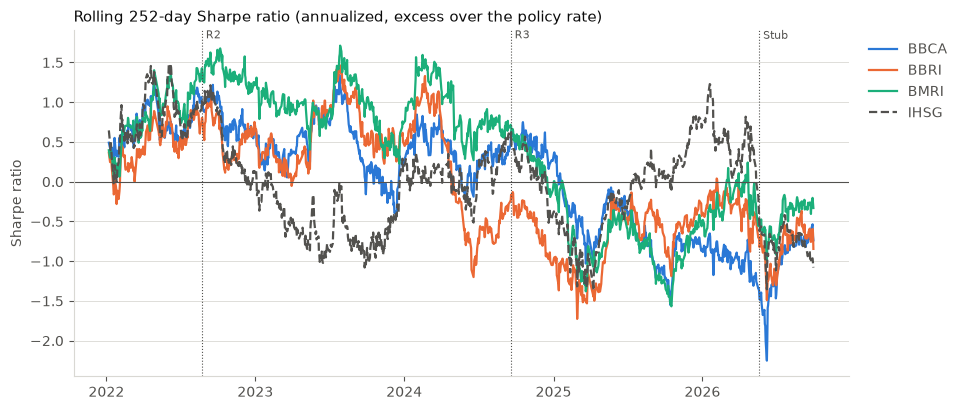

In [8]:
rs = metrics.rolling_sharpe(excess, window=252)
check("rolling Sharpe: first value on the 252nd return day",
      rs.first_valid_index() == ret.index[251] and rs.iloc[:251].isna().all().all() and rs.iloc[251:].notna().all().all(),
      f"{rs.first_valid_index().date()}")


def tidy(ax, title, ylabel):
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED)


def legend_outside(ax):
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0), labelcolor=MUTED)


def mark_regimes(ax):
    top = ax.get_ylim()[1]
    for name in ("R2", "R3", "Stub"):
        start = ret.index[labels == name][0]
        ax.axvline(start, color=MUTED, lw=0.8, ls=":")
        ax.text(start, top, f" {name}", va="top", ha="left", fontsize=8, color=MUTED)


fig, ax = plt.subplots(figsize=(10, 4.5))
for t in TICKERS:
    ax.plot(rs.index, rs[t], color=COLORS[t], lw=1.6, ls="--" if t == "IHSG" else "-", label=t)
ax.axhline(0, color=MUTED, lw=0.8)
tidy(ax, "Rolling 252-day Sharpe ratio (annualized, excess over the policy rate)", "Sharpe ratio")
mark_regimes(ax)
legend_outside(ax)
plt.show()

## 6. Drawdown from the running peak

Each line is the percentage below the highest close so far, from the 2020-12-30 close. The depth and date of each instrument's worst drawdown are in the summary table above.

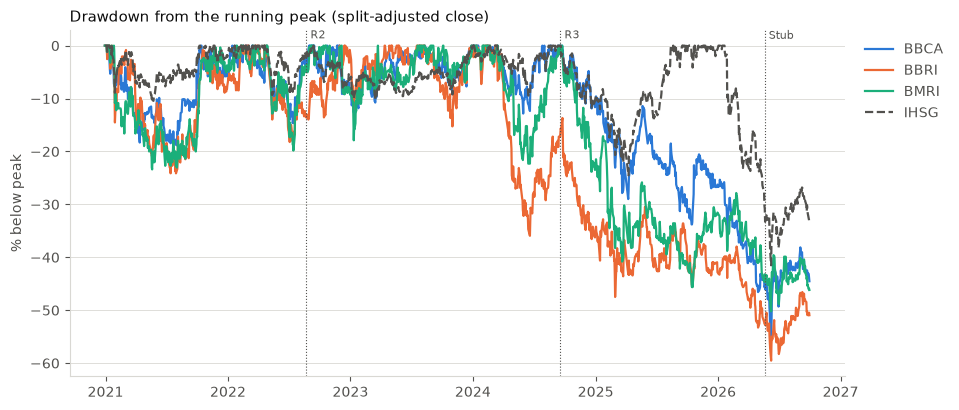

In [9]:
dd = metrics.drawdown_series(close.loc[PRIOR_CLOSE_DAY:]) * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
for t in TICKERS:
    ax.plot(dd.index, dd[t], color=COLORS[t], lw=1.6, ls="--" if t == "IHSG" else "-", label=t)
tidy(ax, "Drawdown from the running peak (split-adjusted close)", "% below peak")
mark_regimes(ax)
legend_outside(ax)
plt.show()

## 7. Sharpe ratio uncertainty: stationary block bootstrap

A Sharpe ratio from one sample is an estimate. The interval below is a percentile interval from a stationary block bootstrap (10,000 resamples, mean block length 10 days, fixed seed). Resampling keeps runs of consecutive days together, which respects short-run dependence. The same resampled dates are used for every instrument in a period, so the days stay paired. Block lengths 5 and 21 are the sensitivity.

`se_lo` is the Lo (2002) i.i.d. standard error for comparison; it ignores serial correlation. The Stub is excluded because 90 days are too few for a reliable interval. Intervals are descriptive: no test of Sharpe differences is run.

In [10]:
rows = []
for period, days in period_days.items():
    if period == "Stub":
        continue
    for t in TICKERS:
        e = excess.loc[days, t]
        row = {"period": period, "ticker": t, "n_days": len(e), "sharpe": metrics.sharpe_ratio(e)}
        for block in (BLOCK, *SENSITIVITY_BLOCKS):
            low, high, reps = metrics.bootstrap_sharpe_ci(e, N_BOOT, block, SEED, LEVEL)
            row[f"ci_low_b{block}"], row[f"ci_high_b{block}"] = low, high
            if block == BLOCK:
                row["se_boot"] = reps.std(ddof=1)
        row["se_lo"] = metrics.lo_sharpe_se(e)
        rows.append(row)

boot = pd.DataFrame(rows).set_index(["period", "ticker"])
boot.round(3)

n_days  sharpe  ci_low_b10  ci_high_b10  se_boot  ci_low_b5  ci_high_b5  ci_low_b21  ci_high_b21  se_lo
period ticker                                                                                                         
Full   BBCA      1381  -0.148      -0.835        0.522    0.345     -0.866       0.560      -0.784        0.502  0.427
       BBRI      1381  -0.134      -0.832        0.585    0.366     -0.872       0.608      -0.821        0.547  0.427
       BMRI      1381   0.133      -0.545        0.829    0.351     -0.603       0.858      -0.512        0.795  0.427
       IHSG      1381  -0.199      -1.005        0.642    0.422     -1.021       0.647      -0.992        0.619  0.427
R1     BBCA       399   0.417      -0.821        1.715    0.652     -0.893       1.720      -0.763        1.664  0.795
       BBRI       399   0.282      -0.997        1.600    0.657     -1.068       1.650      -0.924        1.527  0.795
       BMRI       399   0.669      -0.598        1.988    0.658     -0.674       2.039      -0.480        1.887  0.795
       IHSG       399   0.602      -0.773        2.115    0.735     -0.910       2.176      -0.618        1.947  0.795
R2     BBCA       499   0.508      -0.473        1.518    0.507     -0.587       1.611      -0.364        1.402  0.711
       BBRI       499   0.336      -1.050        1.745    0.717     -0.984       1.717      -1.096        1.742  0.711
       BMRI       499   0.986      -0.147        2.176    0.593     -0.176       2.243      -0.141        2.200  0.711
       IHSG       499  -0.018      -1.227        1.250    0.635     -1.259       1.294      -1.151        1.185  0.711
R3     BBCA       393  -1.309      -2.545       -0.041    0.647     -2.683       0.014      -2.447       -0.124  0.802
       BBRI       393  -1.028      -2.366        0.234    0.662     -2.460       0.343      -2.274        0.145  0.802
       BMRI       393  -1.022      -2.349        0.239    0.661     -2.432       0.351      -2.251        0.201  0.802
       IHSG       393  -0.770      -2.385        0.961    0.851     -2.350       0.906      -2.461        1.089  0.801

PASS  bootstrap interval contains the Sharpe ratio
PASS  bootstrap is reproducible with the fixed seed


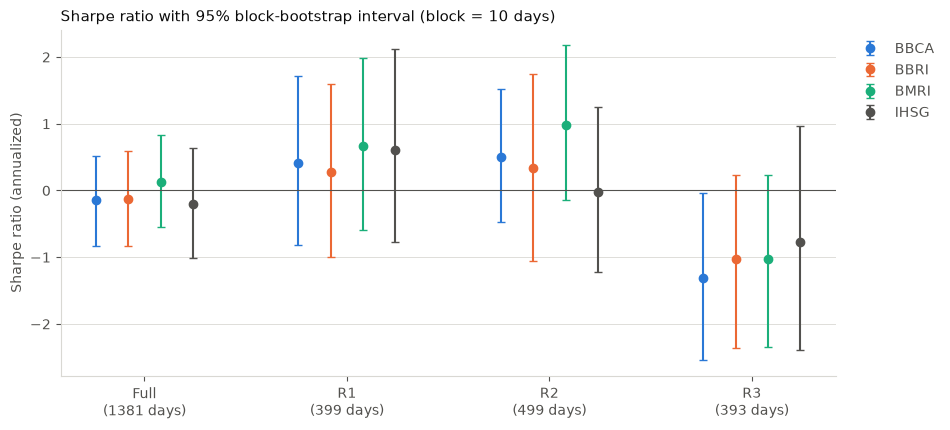

In [11]:
inside = all(boot.loc[i, "ci_low_b10"] < boot.loc[i, "sharpe"] < boot.loc[i, "ci_high_b10"] for i in boot.index)
check("bootstrap interval contains the Sharpe ratio", inside)

e_check = excess.loc[period_days["R1"], "BBCA"]
again = metrics.bootstrap_sharpe_ci(e_check, N_BOOT, BLOCK, SEED, LEVEL)[:2]
check("bootstrap is reproducible with the fixed seed",
      np.allclose(again, boot.loc[("R1", "BBCA"), ["ci_low_b10", "ci_high_b10"]].to_numpy().astype(float)))

periods = ["Full", "R1", "R2", "R3"]
fig, ax = plt.subplots(figsize=(10, 4.5))
for j, t in enumerate(TICKERS):
    x = np.arange(len(periods)) + (j - 1.5) * 0.16
    sr = np.array([boot.loc[(p, t), "sharpe"] for p in periods])
    lo = np.array([boot.loc[(p, t), "ci_low_b10"] for p in periods])
    hi = np.array([boot.loc[(p, t), "ci_high_b10"] for p in periods])
    ax.errorbar(x, sr, yerr=[sr - lo, hi - sr], fmt="o", ms=6, lw=1.5, capsize=3, color=COLORS[t], label=t)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(range(len(periods)))
ax.set_xticklabels([f"{p}\n({len(period_days[p])} days)" for p in periods])
tidy(ax, "Sharpe ratio with 95% block-bootstrap interval (block = 10 days)", "Sharpe ratio (annualized)")
legend_outside(ax)
plt.show()

## 8. Summary and saved tables

Every check above must print PASS. The tables are saved to `reports/` so Tableau can be validated against the same numbers.

In [12]:
out = ROOT / "reports"
out.mkdir(exist_ok=True)
summary.to_csv(out / "02_performance_summary.csv")
boot.to_csv(out / "02_sharpe_bootstrap.csv")
rs.dropna().to_csv(out / "02_rolling_sharpe_252.csv")

n_fail = results.count(False)
print(f"{len(results) - n_fail} passed, {n_fail} failed")
assert n_fail == 0, "At least one check failed. Investigate before using these tables."

11 passed, 0 failed
